# Notebook 14 — Grey Wolf Optimization (GWO) for LSTM Training Hyperparameters

**Project:** Sri Lanka Dengue Disease Prediction | **Depends on:** Notebook 12 + completed Notebook 13.

### Goal
Use **Grey Wolf Optimization**, a nature-inspired population search algorithm, to find training settings that improve **2022–2023 validation MAE** for the **same LSTM architecture** used in Notebook 13.

**We do NOT optimize** the six-month window, feature engineering, district mapping, number of LSTM/Dense units, loss definition, or train/validation/test dates. Those remain fixed. We optimize only:

1. Adam **learning rate** (continuous; searched on log scale).
2. **Dropout rate** (continuous).
3. **Batch size** (discrete: 16, 32, 64).

**No 2024 data is loaded, predicted or scored in this notebook.**

> This is an **exploratory hyperparameter search**. Repeatedly choosing the best validation score can overfit the validation period. The final unbiased comparison belongs in Notebook 15 using the untouched 2024 test period.


## Step 0 — What is Grey Wolf Optimization?

GWO is a metaheuristic inspired by the hierarchy and coordinated movement of grey wolves.

- **Alpha (α):** best candidate solution so far.
- **Beta (β):** second-best candidate.
- **Delta (δ):** third-best candidate.
- **Omega (ω):** other wolves, updated by the leaders.

Each **wolf is a candidate hyperparameter vector**, not an actual animal. In our case, a wolf encodes `(learning rate, dropout, batch size)`.

### How one iteration works
1. Convert each wolf position into valid hyperparameters.
2. Train an LSTM using **training data only**.
3. Compute **validation MAE in original dengue case units**; this is the wolf's *fitness* (lower is better).
4. Identify the alpha, beta, and delta solutions.
5. Update positions according to the GWO equations.
6. Repeat for a small budget; save the best validation solution.

**Computation:** Default = 4 wolves × 3 iterations = 12 candidate evaluations (some may repeat and be cached), plus one final saved-model fit. TensorFlow training can be slow on a laptop. To try a quick smoke test, temporarily set `N_WOLVES=3`, `N_ITERATIONS=1`.


## Step 1 — Import packages and locate Notebook 12/13 outputs

TensorFlow must be installed in the selected `.venv` kernel. We also require the Notebook 13 baseline configuration so the network topology stays identical.

In [1]:
from pathlib import Path
import os, json, random, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "data" / "final" / "model_inputs").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Missing data/final/model_inputs; run Notebook 12 first.")
INPUT_DIR = PROJECT_ROOT / "data" / "final" / "model_inputs"
MODELS_DIR = PROJECT_ROOT / "models"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
for d in [MODELS_DIR, METRICS_DIR, TABLES_DIR, FIGURES_DIR]: d.mkdir(parents=True, exist_ok=True)
config_path = MODELS_DIR / "notebook13_fixed_lstm_config.json"
baseline_metrics_path = METRICS_DIR / "notebook13_validation_metrics.json"
if not config_path.exists() or not baseline_metrics_path.exists():
    raise FileNotFoundError("Run and save Notebook 13 first (baseline config and metrics required).")
BASELINE_CONFIG = json.loads(config_path.read_text(encoding="utf-8"))
BASELINE_METRICS = json.loads(baseline_metrics_path.read_text(encoding="utf-8"))
assert BASELINE_CONFIG["variant"] == "weather_only"
assert BASELINE_METRICS["validation_only"] is True
print("Baseline validation MAE:", BASELINE_METRICS["metrics"]["MAE_cases"])


Baseline validation MAE: 89.07862766408147


In [2]:
try:
    import tensorflow as tf
except ImportError as exc:
    raise ImportError("Install TensorFlow in your .venv: python -m pip install tensorflow") from exc
print("TensorFlow:", tf.__version__)


TensorFlow: 2.21.0


## Step 2 — Load only train and validation data

The **same arrays** and feature ordering used in Notebook 13 are required for a fair comparison. Never refit scalers in this notebook. We will not even open the test `.npz` file.

In [3]:
def load_partition(partition):
    path = INPUT_DIR / f"weather_only_{partition}.npz"
    metadata_path = INPUT_DIR / f"weather_only_{partition}_metadata.csv"
    with np.load(path, allow_pickle=False) as data:
        X = data["X"].astype(np.float32)
        y_raw = data["y_raw"].astype(np.float32)
        y_log = data["y_log1p"].astype(np.float32)
        feature_names = data["feature_names"].tolist()
    meta = pd.read_csv(metadata_path, parse_dates=["target_date", "feature_date"])
    assert len(X) == len(y_raw) == len(y_log) == len(meta)
    assert np.isfinite(X).all() and np.isfinite(y_log).all()
    assert (meta["partition"] == partition).all()
    return X, y_raw, y_log, feature_names, meta

X_train, y_train_raw, y_train_log, train_names, train_meta = load_partition("train")
X_val, y_val_raw, y_val_log, val_names, val_meta = load_partition("validation")
assert train_names == val_names == BASELINE_CONFIG["feature_names"]
assert tuple(X_train.shape[1:]) == (BASELINE_CONFIG["sequence_length"], BASELINE_CONFIG["n_features"])
assert val_meta["target_date"].between("2022-01-01", "2023-12-01").all()
assert train_meta["target_date"].max() <= pd.Timestamp("2021-12-01")
print("Train:", X_train.shape, "Validation:", X_val.shape)


Train: (3300, 6, 33) Validation: (600, 6, 33)


## Step 3 — Define a fixed architecture and fitness function

The architecture is **exactly** Notebook 13's: `LSTM(32) → Dense(16, relu) → Dropout(rate) → Dense(1)`.

We optimize validation **MAE in case units**, not the MSE used for gradient updates. Why? MSE on log cases is a useful differentiable training loss, while case-scale MAE is easier to interpret in public-health terms.

For comparability, every wolf is evaluated using the same random seed, epoch budget and early-stopping rule. This reduces—but does not eliminate—stochastic noise.

In [4]:
assert BASELINE_CONFIG["lstm_units"] == 32 and BASELINE_CONFIG["dense_units"] == 16
assert BASELINE_CONFIG["loss"] == "mse_on_log1p_cases"

def build_fixed_lstm(learning_rate, dropout):
    net = tf.keras.Sequential([
        tf.keras.layers.Input(shape=X_train.shape[1:]),
        tf.keras.layers.LSTM(32),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dropout(float(dropout)),
        tf.keras.layers.Dense(1),
    ])
    net.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=float(learning_rate)), loss="mse")
    return net

def to_cases(log_predictions):
    return np.maximum(0.0, np.expm1(np.clip(np.asarray(log_predictions, dtype=float).reshape(-1), -20.0, 20.0)))

def metrics(actual, predicted):
    return {"MAE_cases": float(mean_absolute_error(actual, predicted)),
            "RMSE_cases": float(np.sqrt(mean_squared_error(actual, predicted)))}

# Match the baseline's maximum epochs and early stopping for a fair comparison.
MAX_EPOCHS = int(BASELINE_CONFIG["max_epochs"])
PATIENCE = int(BASELINE_CONFIG["early_stopping_patience"])
print("Candidate training budget:", MAX_EPOCHS, "epochs max, patience", PATIENCE)


Candidate training budget: 40 epochs max, patience 6


## Step 4 — Encode a wolf as a 3-dimensional position

We store all three position coordinates in the continuous interval `[0, 1]`, then decode them into valid training settings:

- `position[0]`: mapped to **log10(learning rate)** from 0.0003 to 0.003.
- `position[1]`: mapped linearly to dropout from 0.0 to 0.4.
- `position[2]`: mapped to one of the **discrete** batch sizes `[16, 32, 64]`.

Using a log scale for learning rate is more meaningful than searching linearly: changes from 0.0003 to 0.0006 can matter as much as changes from 0.0015 to 0.003.


In [5]:
BATCH_CHOICES = (16, 32, 64)

def decode_wolf(position):
    x = np.clip(np.asarray(position, dtype=float), 0.0, 1.0)
    learning_rate = 10 ** (np.log10(0.0003) + x[0] * (np.log10(0.003) - np.log10(0.0003)))
    dropout = 0.4 * x[1]
    batch_index = min(int(x[2] * len(BATCH_CHOICES)), len(BATCH_CHOICES) - 1)
    return {"learning_rate": float(learning_rate), "dropout": float(dropout),
            "batch_size": int(BATCH_CHOICES[batch_index])}

for example in [np.array([0., 0., 0.]), np.array([0.5, 0.5, 0.5]), np.array([1., 1., 1.])]:
    print(example, "=>", decode_wolf(example))


[0. 0. 0.] => {'learning_rate': 0.00030000000000000014, 'dropout': 0.0, 'batch_size': 16}
[0.5 0.5 0.5] => {'learning_rate': 0.0009486832980505141, 'dropout': 0.2, 'batch_size': 32}
[1. 1. 1.] => {'learning_rate': 0.003000000000000001, 'dropout': 0.4, 'batch_size': 64}


## Step 5 — Evaluate a wolf (this is the expensive step)

**Fitness** = MAE between predicted and actual dengue cases on **2022–2023 validation samples**. Lower is better.

We use an in-memory cache so that the same decoded settings are not trained twice. The cache key is rounded to a practical precision; no scores are fabricated. Each uncached evaluation trains a fresh model from a fixed seed, and then clears its TensorFlow state to limit memory usage.

In [6]:
fitness_cache = {}
trial_rows = []

def evaluate_wolf(position):
    hp = decode_wolf(position)
    key = (round(hp["learning_rate"], 8), round(hp["dropout"], 5), hp["batch_size"])
    if key in fitness_cache:
        return fitness_cache[key]
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    net = build_fixed_lstm(hp["learning_rate"], hp["dropout"])
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    h = net.fit(X_train, y_train_log, validation_data=(X_val, y_val_log),
                epochs=MAX_EPOCHS, batch_size=hp["batch_size"],
                callbacks=[early_stop], verbose=0, shuffle=False)
    prediction = to_cases(net.predict(X_val, verbose=0))
    score = metrics(y_val_raw, prediction)
    result = float(score["MAE_cases"])
    fitness_cache[key] = result
    trial_rows.append({"trial": len(trial_rows) + 1, **hp, **score,
                       "epochs_completed": len(h.history["loss"]),
                       "best_val_log_mse": float(min(h.history["val_loss"]))})
    print(f"Trial {len(trial_rows):02d} | lr={hp['learning_rate']:.6f}, dropout={hp['dropout']:.3f}, "
          f"batch={hp['batch_size']} | validation MAE={result:.3f}")
    del net, h
    tf.keras.backend.clear_session()
    gc.collect()
    return result


## Step 6 — Understand the GWO update equations

At each iteration, each wolf is attracted toward three leaders: alpha, beta and delta.

For each leader, calculate:

\[
\vec{D}=|\vec{C}\odot\vec{X}_{leader}-\vec{X}_{wolf}|,\qquad
\vec{X}_{candidate}=\vec{X}_{leader}-\vec{A}\odot\vec{D}
\]

where \(\vec{A}=2a\vec{r}_1-a\), \(\vec{C}=2\vec{r}_2\), and \(a\) decreases linearly from 2 to 0. The next position is the **average of the three leader-guided candidates**.

**Intuition:** early iterations explore widely; later iterations exploit the best-known region. The algorithm does not guarantee a global optimum, especially with a small number of wolves and expensive neural-network training.

In [7]:
def gwo_update(positions, leaders, a, rng):
    updated = np.empty_like(positions)
    for i, current in enumerate(positions):
        guided = []
        for leader in leaders:
            r1, r2 = rng.random(current.size), rng.random(current.size)
            A = 2.0 * a * r1 - a
            C = 2.0 * r2
            D = np.abs(C * leader - current)
            guided.append(leader - A * D)
        updated[i] = np.clip(np.mean(guided, axis=0), 0.0, 1.0)
    return updated

# Lightweight mathematical test (no neural-network training).
_test_rng = np.random.default_rng(7)
_test_pos = _test_rng.random((4, 3))
_test_new = gwo_update(_test_pos, _test_pos[:3], a=1.5, rng=_test_rng)
assert _test_new.shape == (4, 3)
assert np.isfinite(_test_new).all() and ((_test_new >= 0) & (_test_new <= 1)).all()
print("PASS: GWO position-update numerical sanity check")


PASS: GWO position-update numerical sanity check


## Step 7 — Run a small, reproducible GWO search

**Default:** four wolves and three iterations. Each candidate model uses the full Notebook 13 epoch budget, so this may take substantial time on a CPU. Change only the two values below to control the **number of candidates**, and record the chosen budget in your paper.

We track the best **ever** solution across iterations (elitism). This prevents losing a strong candidate after a position update.

**Important:** If you change the search space or number of iterations after inspecting results, document that as additional tuning on the same validation set.

In [8]:
N_WOLVES = 4      # Minimum 3: alpha, beta, delta.
N_ITERATIONS = 3   # Start with 1 for a quick run.
assert N_WOLVES >= 3 and N_ITERATIONS >= 1
rng = np.random.default_rng(SEED)
positions = rng.random((N_WOLVES, 3))
search_history = []
best_ever_score = float("inf")
best_ever_position = None

for iteration in range(N_ITERATIONS):
    print(f"\n--- GWO iteration {iteration+1}/{N_ITERATIONS} ---")
    scores = np.asarray([evaluate_wolf(position) for position in positions], dtype=float)
    order = np.argsort(scores)
    leaders = positions[order[:3]].copy()
    if scores[order[0]] < best_ever_score:
        best_ever_score = float(scores[order[0]])
        best_ever_position = positions[order[0]].copy()
    search_history.append({"iteration": iteration + 1,
                           "alpha_MAE_cases": float(scores[order[0]]),
                           "beta_MAE_cases": float(scores[order[1]]),
                           "delta_MAE_cases": float(scores[order[2]]),
                           "best_so_far_MAE_cases": best_ever_score,
                           "unique_models_trained": len(trial_rows)})
    print("Best-so-far validation MAE:", round(best_ever_score, 3))
    if iteration < N_ITERATIONS - 1:
        a = 2.0 * (1.0 - iteration / max(N_ITERATIONS - 1, 1))
        positions = gwo_update(positions, leaders, a=a, rng=rng)
        # Keep the best-ever wolf in the population (elitism).
        positions[0] = best_ever_position

assert best_ever_position is not None
best_hp = decode_wolf(best_ever_position)
print("Best hyperparameters:", best_hp)
print("Best searched validation MAE:", best_ever_score)



--- GWO iteration 1/3 ---

Trial 01 | lr=0.001783, dropout=0.176, batch=64 | validation MAE=94.785
Trial 02 | lr=0.001494, dropout=0.038, batch=64 | validation MAE=89.021
Trial 03 | lr=0.001731, dropout=0.314, batch=16 | validation MAE=85.065
Trial 04 | lr=0.000846, dropout=0.148, batch=64 | validation MAE=95.193
Best-so-far validation MAE: 85.065

--- GWO iteration 2/3 ---
Trial 05 | lr=0.001407, dropout=0.040, batch=64 | validation MAE=88.979
Trial 06 | lr=0.000861, dropout=0.152, batch=32 | validation MAE=88.719
Trial 07 | lr=0.001457, dropout=0.172, batch=64 | validation MAE=94.096
Best-so-far validation MAE: 85.065

--- GWO iteration 3/3 ---
Trial 08 | lr=0.002328, dropout=0.078, batch=32 | validation MAE=96.822
Trial 09 | lr=0.001212, dropout=0.188, batch=64 | validation MAE=94.375
Trial 10 | lr=0.001222, dropout=0.248, batch=64 | validation MAE=96.204
Best-so-far validation MAE: 85.065
Best hyperparameters: {'learning_rate': 0.0017308560750108767, 'dropout': 0.31442572211078157

## Step 8 — Visualize search convergence

This figure shows whether the best validation MAE decreased as more candidates were tested. A flat curve does not mean convergence to the global optimum: it may simply mean the small search budget did not find a better candidate.

,iteration,alpha_MAE_cases,beta_MAE_cases,delta_MAE_cases,best_so_far_MAE_cases,unique_models_trained
0,1,85.06486,89.021377,94.784600,85.06486,4
1,2,85.06486,88.718800,88.979295,85.06486,7
2,3,85.06486,94.374787,96.203873,85.06486,10


,trial,learning_rate,dropout,batch_size,MAE_cases,RMSE_cases,epochs_completed,best_val_log_mse
2,3,0.001731,0.314426,16,85.064860,178.239409,21,0.508971
5,6,0.000861,0.152330,32,88.718800,176.879507,34,0.602222
4,5,0.001407,0.040067,64,88.979295,180.012502,40,0.675960
1,2,0.001494,0.037671,64,89.021377,179.828663,40,0.675408
6,7,0.001457,0.172106,64,94.095856,193.615781,40,0.744370
8,9,0.001212,0.187830,64,94.374787,197.336343,40,0.779599
0,1,0.001783,0.175551,64,94.784600,185.846161,40,0.755913
3,4,0.000846,0.148319,64,95.192731,190.317538,40,0.814913
9,10,0.001222,0.247929,64,96.203873,189.273274,35,0.886718
7,8,0.002328,0.077528,32,96.821505,205.953545,24,0.605935


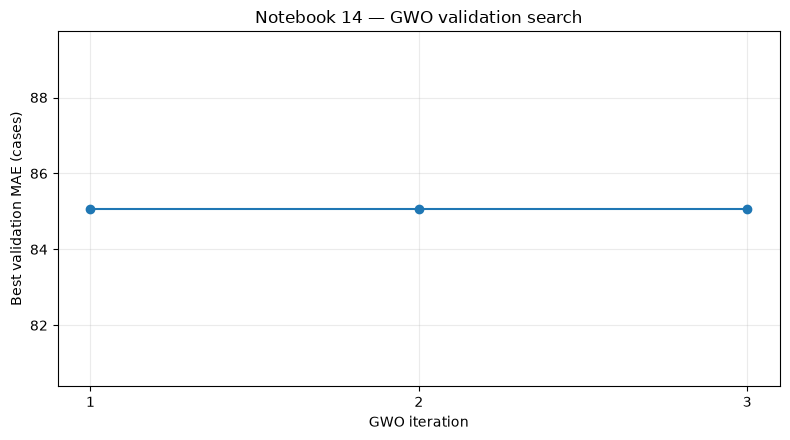

In [9]:
search_df = pd.DataFrame(search_history)
trials_df = pd.DataFrame(trial_rows)
display(search_df)
display(trials_df.sort_values("MAE_cases").head(10))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(search_df["iteration"], search_df["best_so_far_MAE_cases"], marker="o")
ax.set(xlabel="GWO iteration", ylabel="Best validation MAE (cases)",
       title="Notebook 14 — GWO validation search")
ax.set_xticks(search_df["iteration"])
ax.grid(alpha=0.25); fig.tight_layout()
fig.savefig(FIGURES_DIR / "notebook14_gwo_convergence.png", dpi=160)
plt.show()


## Step 9 — Train and save the selected GWO model

Rebuild the same architecture using the **best search hyperparameters**, then train a fresh model using training labels only. Early stopping uses validation loss as in Notebook 13.

Because neural networks are stochastic, this final fit can have a different validation MAE than the best candidate evaluated during the search. **Report the actual saved-model score**, not just the best search score. We still do not load 2024 test data.

In [10]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
selected_model = build_fixed_lstm(best_hp["learning_rate"], best_hp["dropout"])
selected_history = selected_model.fit(
    X_train, y_train_log, validation_data=(X_val, y_val_log),
    epochs=MAX_EPOCHS, batch_size=best_hp["batch_size"], shuffle=False, verbose=2,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=PATIENCE, restore_best_weights=True)])
selected_pred_log = selected_model.predict(X_val, verbose=0).reshape(-1)
selected_pred_cases = to_cases(selected_pred_log)
selected_metrics = metrics(y_val_raw, selected_pred_cases)
print("Saved-model validation metrics:", selected_metrics)


Epoch 1/40
207/207 - 2s - 9ms/step - loss: 6.3088 - val_loss: 2.1279
Epoch 2/40
207/207 - 0s - 2ms/step - loss: 2.6820 - val_loss: 1.2763
Epoch 3/40
207/207 - 0s - 2ms/step - loss: 2.2156 - val_loss: 1.0549
Epoch 4/40
207/207 - 0s - 2ms/step - loss: 1.9922 - val_loss: 0.8812
Epoch 5/40
207/207 - 0s - 2ms/step - loss: 1.8073 - val_loss: 0.9781
Epoch 6/40
207/207 - 0s - 2ms/step - loss: 1.7226 - val_loss: 1.0103
Epoch 7/40
207/207 - 0s - 2ms/step - loss: 1.6246 - val_loss: 0.8158
Epoch 8/40
207/207 - 0s - 2ms/step - loss: 1.5276 - val_loss: 0.8006
Epoch 9/40
207/207 - 0s - 2ms/step - loss: 1.3509 - val_loss: 0.8792
Epoch 10/40
207/207 - 0s - 2ms/step - loss: 1.3346 - val_loss: 0.7882
Epoch 11/40
207/207 - 0s - 2ms/step - loss: 1.2882 - val_loss: 0.6306
Epoch 12/40
207/207 - 0s - 2ms/step - loss: 1.2717 - val_loss: 0.6196
Epoch 13/40
207/207 - 0s - 2ms/step - loss: 1.2552 - val_loss: 0.6136
Epoch 14/40
207/207 - 0s - 2ms/step - loss: 1.1482 - val_loss: 0.5675
Epoch 15/40
207/207 - 0s - 2m

## Step 10 — Compare with Notebook 13 on **the same validation period**

Both models are evaluated on identical validation targets (January 2022–December 2023) and use the same architecture and input features. Differences are attributable to the search-selected training settings **and training randomness**, not a new LSTM topology.

**Important:** The winner on validation is not necessarily the winner on 2024 test data. Avoid calling the GWO model "better" without final independent test evaluation.

In [11]:
baseline = BASELINE_METRICS["metrics"]
comparison = pd.DataFrame([
    {"model": "Fixed LSTM baseline (Notebook 13)", **baseline},
    {"model": "GWO-tuned LSTM (Notebook 14)", **selected_metrics},
])
comparison["period"] = "validation_2022_2023"
display(comparison)
print("Validation MAE change (baseline - GWO):",
      round(float(baseline["MAE_cases"] - selected_metrics["MAE_cases"]), 3), "cases")


,model,MAE_cases,RMSE_cases,n_samples,period
0,Fixed LSTM baseline (Notebook 13),89.078628,177.532125,600.0,validation_2022_2023
1,GWO-tuned LSTM (Notebook 14),85.064860,178.239409,NaN,validation_2022_2023


Validation MAE change (baseline - GWO): 4.014 cases


## Step 11 — Save models, logs, predictions, and experiment metadata

Save everything needed to reproduce and audit the search: all unique candidate trials, iteration convergence, best decoded hyperparameters, training history, validation predictions and the selected `.keras` model.

The model is **not** a final test-evaluated model yet. Notebook 15 will compare frozen models on the untouched 2024 test data **once**, without further tuning based on test scores.

In [12]:
selected_model_path = MODELS_DIR / "notebook14_gwo_lstm_weather_only.keras"
selected_model.save(selected_model_path)
manifest = {
    "dataset": "weather_only", "training_target": "log1p_dengue_cases",
    "fitness": "validation_MAE_in_original_case_units",
    "train_target_end": "2021-12-01", "validation_target_range": ["2022-01-01", "2023-12-01"],
    "test_accessed": False, "architecture": "LSTM(32)-Dense(16,relu)-Dropout-Dense(1)",
    "seed": SEED, "wolves": N_WOLVES, "iterations": N_ITERATIONS,
    "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "search_space": {"learning_rate": [0.0003, 0.003],
                     "dropout": [0.0, 0.4], "batch_size": list(BATCH_CHOICES)},
    "best_hyperparameters": best_hp, "best_search_validation_MAE_cases": best_ever_score,
    "saved_model_validation_metrics": selected_metrics,
    "baseline_validation_metrics": baseline,
    "n_unique_candidate_models": len(trial_rows),
    "model_path": str(selected_model_path.relative_to(PROJECT_ROOT)),
    "note": "Validation-driven hyperparameter search; final independent evaluation remains for Notebook 15.",
}
(MODELS_DIR / "notebook14_gwo_search_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
(METRICS_DIR / "notebook14_validation_metrics.json").write_text(json.dumps({
    "dataset": "weather_only", "validation_only": True, "metrics": selected_metrics}, indent=2), encoding="utf-8")
trials_df.to_csv(TABLES_DIR / "notebook14_gwo_trials.csv", index=False)
search_df.to_csv(TABLES_DIR / "notebook14_gwo_convergence.csv", index=False)
comparison.to_csv(TABLES_DIR / "notebook14_validation_model_comparison.csv", index=False)
pd.DataFrame(selected_history.history).to_csv(TABLES_DIR / "notebook14_selected_training_history.csv", index=False)
validation_predictions = val_meta[["administrative_district", "target_date"]].copy()
validation_predictions["actual_cases"] = y_val_raw
validation_predictions["predicted_cases"] = selected_pred_cases
validation_predictions.to_csv(TABLES_DIR / "notebook14_validation_predictions.csv", index=False)
assert len(trials_df) > 0 and selected_model_path.is_file()
print("NOTEBOOK 14 COMPLETED — validation-only GWO search; 2024 test untouched.")


NOTEBOOK 14 COMPLETED — validation-only GWO search; 2024 test untouched.


## How to interpret the experiment — and what to do next

### What the notebook demonstrates
- **Optimization is not magic:** GWO is a heuristic search. It proposes candidate settings and uses actual LSTM training/validation to assess them.
- **Alpha, beta, delta:** the three best candidates in an iteration guide other wolves.
- **Fitness:** validation MAE measured in **case units**, with lower being better.
- **Fixed architecture:** the number of LSTM units, Dense units, sequence length, predictors, loss and chronological partitions remain unchanged.
- **Reproducibility:** all trials and settings are saved, including runs that performed poorly.

### Research cautions
1. A 4-wolf × 3-iteration search is a **small demonstration budget**, not evidence of globally optimal hyperparameters.
2. Validation MAE is repeatedly consulted, so the selected model may be **overfit to validation**. Use the untouched 2024 period for final evaluation in Notebook 15.
3. Do not compare the weather-only and population-inclusive models as if their training windows were identical; they start in different years.
4. A single random seed cannot establish statistical significance. Later research can repeat training across seeds or use blocked temporal validation.
5. GWO changing dropout is a **training-hyperparameter** change, while the network's layer topology stays fixed. If your research protocol requires *all* training settings fixed too, treat Notebook 14 as a **separate optimization experiment**, not a controlled preprocessing comparison.

**Next:** Notebook 15 — Final Evaluation. Freeze model selection first, then load the 2024 test arrays for the first time and report test metrics on the original dengue case scale.
